# Data Preperation

## Libraries

In [18]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web
import matplotlib.pyplot as plt
import statsmodels.api as sm
import xlrd

## Data Download

### Yahoo Finance

In [19]:
sp500 = yf.download("^GSPC", start="1990-01-01", end="2025-12-31", auto_adjust=False)

[*********************100%***********************]  1 of 1 completed


In [20]:
sp500["ret"] = np.log(sp500[("Adj Close", "^GSPC")]).diff()

In [21]:
sp500

Price,Adj Close,Close,High,Low,Open,Volume,ret
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,
Date,,,,,,,
1990-01-02,359.690002,359.690002,359.690002,351.980011,353.399994,162070000,NaN
1990-01-03,358.760010,358.760010,360.589996,357.890015,359.690002,192330000,-0.002589
1990-01-04,355.670013,355.670013,358.760010,352.890015,358.760010,177000000,-0.008650
1990-01-05,352.200012,352.200012,355.670013,351.350006,355.670013,158530000,-0.009804
1990-01-08,353.790009,353.790009,354.239990,350.540009,352.200012,140110000,0.004504
...,...,...,...,...,...,...,...
2025-12-23,6909.790039,6909.790039,6910.879883,6868.810059,6872.410156,3820560000,0.004540
2025-12-24,6932.049805,6932.049805,6937.319824,6904.910156,6904.910156,1798270000,0.003216


In [22]:
rv = sp500["ret"].pow(2).rolling(21).sum()
rv.name = "RV"

In [23]:
vix = yf.download("^VIX", start="1990-01-01", end="2025-12-31", auto_adjust=False)

[*********************100%***********************]  1 of 1 completed


In [24]:
vix_daily = vix["Adj Close"]

iv = (vix_daily / 100) ** 2
iv = iv / 12
iv.name = "IV"

In [25]:
vix

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^VIX,^VIX,^VIX,^VIX,^VIX,^VIX
Date,,,,,,
1990-01-02,17.240000,17.240000,17.240000,17.240000,17.240000,0
1990-01-03,18.190001,18.190001,18.190001,18.190001,18.190001,0
1990-01-04,19.219999,19.219999,19.219999,19.219999,19.219999,0
1990-01-05,20.110001,20.110001,20.110001,20.110001,20.110001,0
1990-01-08,20.260000,20.260000,20.260000,20.260000,20.260000,0
...,...,...,...,...,...,...
2025-12-23,14.000000,14.000000,14.450000,13.640000,14.090000,0
2025-12-24,13.470000,13.470000,14.160000,13.380000,14.090000,0


In [ ]:
df = pd.concat([iv, rv], axis=1).dropna()
df = df.rename(columns={"^VIX": "IV"})
df["VRP"] = df["IV"] - df["RV"]

KeyError: 'iv'

In [ ]:
df["VRP"].mean()

np.float64(0.012971950054569307)

In [ ]:
rf = web.DataReader("TB3MS", "fred", start="1990-01-01") / 100
rf = rf.resample("D").ffill()
rf["rf_daily"] = rf["TB3MS"] / 252

In [ ]:
rf

,TB3MS
DATE,
1990-01-31,0.0764
1990-02-28,0.0774
1990-03-31,0.0790
1990-04-30,0.0777
1990-05-31,0.0774
...,...
2025-11-30,0.0378
2025-12-31,0.0359
2026-01-31,0.0357


In [ ]:
df["ret"] = sp500["ret"]
df = df.merge(rf["rf_daily"], left_index=True, right_index=True, how="left")

In [ ]:
df["excess_ret"] = df["ret"] - df["rf_daily"]

In [ ]:
df_monthly = df.resample("ME").last()

In [ ]:
df_monthly["ret_fwd"] = df_monthly["excess_ret"].shift(-1)

In [ ]:
df[["excess_ret", "VRP"]].corr()

,excess_ret,VRP
excess_ret,1.000000,-0.426853
VRP,-0.426853,1.000000


array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>], dtype=object)

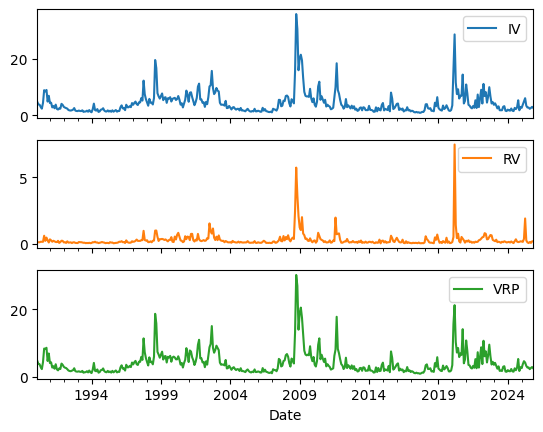

In [ ]:
df[["IV", "RV", "VRP"]].plot(subplots=True)

In [ ]:
df["RV_ann"] = df["RV"] * 12
df["IV_ann"] = df["IV"] * 12
df["VRP_ann"] = df["VRP"] * 12

In [ ]:
df

,IV,RV,VRP,ret,rf,excess_ret,ret_fwd,RV_ann,IV_ann,VRP_ann
Date,,,,,,,,,,
1990-02-28,4.835601,0.100781,4.734820,0.008503,0.006450,0.002053,0.017382,1.209372,58.027211,56.817839
1990-03-31,3.892729,0.102863,3.789866,0.023966,0.006583,0.017382,-0.033730,1.234353,46.712746,45.478393
1990-04-30,3.810304,0.096950,3.713354,-0.027255,0.006475,-0.033730,0.081551,1.163403,45.723650,44.560247
1990-05-31,3.017169,0.134186,2.882983,0.088001,0.006450,0.081551,-0.015368,1.610238,36.206031,34.595794
1990-06-30,2.402500,0.135575,2.266925,-0.008926,0.006442,-0.015368,-0.011587,1.626897,28.830000,27.203103
...,...,...,...,...,...,...,...,...,...,...
2025-07-31,2.795584,0.037021,2.758563,0.021435,0.003542,0.017894,0.015454,0.444247,33.547005,33.102758
2025-08-31,2.359296,0.113962,2.245334,0.018887,0.003433,0.015454,0.031447,1.367538,28.311551,26.944012
2025-09-30,2.650384,0.045801,2.604583,0.034714,0.003267,0.031447,0.019250,0.549612,31.804611,31.254999


### Cay Data

In [ ]:
cay = pd.read_csv("data/cay_current.csv")

In [ ]:
cay

,date,c,w,y,cay=c-0.218 a-0.801y+0.441
0,1952-03-31,9.155654,10.964372,8.979659,0.015105
1,1952-06-30,9.171140,10.981857,8.982086,0.024837
2,1952-09-30,9.171598,10.978478,8.996057,0.014840
3,1952-12-31,9.201695,10.972688,9.026059,0.022166
4,1953-03-31,9.209631,10.973457,9.036562,0.021521
...,...,...,...,...,...
266,2018-09-30,10.591508,12.647892,10.369712,-0.029345
267,2018-12-31,10.593748,12.605162,10.372724,-0.020207
268,2019-03-31,10.595604,12.650841,10.392760,-0.044354
269,2019-06-30,10.605677,12.662190,10.393868,-0.037642


In [ ]:
cay = cay.rename(columns={"cay=c-0.218 a-0.801y+0.441": "cay"})

### Shiller Data

In [ ]:
df_shiller = pd.read_excel("data/ie_data.xls", sheet_name="Data", engine="xlrd", skiprows=7)

In [ ]:
df_shiller.columns

Index(['Date', 'P', 'D', 'E', 'CPI', 'Fraction', 'Rate GS10', 'Price',
       'Dividend', 'Price.1', 'Earnings', 'Earnings.1', 'CAPE', 'Unnamed: 13',
       'TR CAPE', 'Unnamed: 15', 'Yield', 'Returns', 'Returns.1',
       'Real Return', 'Real Return.1', 'Returns.2'],
      dtype='object')

In [ ]:
df_shiller.tail(20)

,Date,P,D,E,CPI,Fraction,Rate GS10,Price,Dividend,Price.1,...,CAPE,Unnamed: 13,TR CAPE,Unnamed: 15,Yield,Returns,Returns.1,Real Return,Real Return.1,Returns.2
1845,2024.10,5792.319565,73.877418,203.570000,315.664,2024.791667,4.1,6017.483364,76.749242,4.022194e+06,...,36.587211,NaN,39.375226,NaN,0.015221,0.982514,40.006731,NaN,NaN,NaN
1846,2024.11,5929.916,74.354836,206.870000,315.493,2024.875000,4.36,6163.767567,77.287086,4.124278e+06,...,37.350196,NaN,40.176632,NaN,0.012564,1.001225,39.328482,NaN,NaN,NaN
1847,2024.12,6010.908571,74.832255,210.170000,315.605,2024.958333,4.39,6245.736917,77.755729,4.183460e+06,...,37.711192,NaN,40.544845,NaN,0.012630,0.984603,39.362679,NaN,NaN,NaN
1848,2025.01,5979.5155,75.269937,212.343333,317.671,2025.041667,4.63,6172.709881,77.701861,4.138883e+06,...,37.129220,NaN,39.899969,NaN,0.011804,1.018269,38.504542,NaN,NaN,NaN
1849,2025.02,6038.69,75.707619,214.516667,319.082,2025.125000,4.45,6206.230046,77.808084,4.165706e+06,...,37.187176,NaN,39.943400,NaN,0.013572,1.017426,39.034610,NaN,NaN,NaN
1850,2025.03,5683.983333,76.145301,216.690000,319.799,2025.208333,4.28,5828.584997,78.082453,3.916593e+06,...,34.784750,NaN,37.348615,NaN,0.016749,1.003567,39.625790,NaN,NaN,NaN
1851,2025.04,5369.495714,76.546867,218.636667,320.795,2025.291667,4.28,5489.001495,78.250527,3.692788e+06,...,32.621270,NaN,35.015341,NaN,0.018767,0.992343,39.643654,NaN,NaN,NaN
1852,2025.05,5810.919524,76.948434,220.583333,321.465,2025.375000,4.42,5927.869103,78.497085,3.992442e+06,...,35.076697,NaN,37.637336,NaN,0.014912,1.006896,39.258095,NaN,NaN,NaN
1853,2025.06,6029.9515,77.350000,222.530000,322.561,2025.458333,4.38,6130.408319,78.638623,4.133266e+06,...,36.111092,NaN,38.732625,NaN,0.014485,1.002847,39.394513,NaN,NaN,NaN
1854,2025.07,6296.498182,77.726667,226.770000,323.048,2025.541667,4.39,6391.745366,78.902439,4.313899e+06,...,37.474246,NaN,40.178756,NaN,0.013527,1.014158,39.447119,NaN,NaN,NaN


In [ ]:
df_shiller["Date"] = pd.to_datetime(
    df_shiller["Date"].map(lambda x: f"{x:.2f}"),
    format="%Y.%m",
    errors="coerce"
)

In [ ]:
p = pd.to_numeric(df_shiller["P"], errors="coerce")
e = pd.to_numeric(df_shiller["E"], errors="coerce")
d = pd.to_numeric(df_shiller["D"], errors="coerce")

df_shiller["log_PE"] = np.log(p / e)
df_shiller["log_PD"] = np.log(p / d)

### Merge

In [ ]:
shiller_factors = df_shiller.copy()

if "Date" in shiller_factors.columns:
    shiller_factors = shiller_factors.set_index("Date")

shiller_factors = shiller_factors[["log_PE", "log_PD"]]
shiller_factors = shiller_factors[shiller_factors.index.notna()]
shiller_factors.index = shiller_factors.index.to_period("M").to_timestamp("M")

cay_series = cay[["date", "cay"]].copy()
cay_series["date"] = pd.to_datetime(cay_series["date"])
cay_series = cay_series.set_index("date").sort_index()

# Monthly Index erzeugen
cay_series = cay_series.resample("ME").ffill()

df = df.join(shiller_factors, how="left")
df = df.join(cay_series[["cay"]], how="left")


df[["log_PE", "log_PD", "cay"]].tail()

,log_PE,log_PD,cay
Date,,,
2025-07-31,3.323813,4.394551,NaN
2025-08-31,3.322990,4.407418,NaN
2025-09-30,3.331752,4.429557,NaN
2025-10-31,3.329536,4.447924,NaN
2025-11-30,3.305924,4.444307,NaN


In [ ]:
df.to_csv("data/data.csv")

### FRED DATA

In [ ]:
start = "1985-01-01"  # früher starten wegen rolling mean!
end = df.index.max()

fred_series = {
    "BAA": "BAA",        # Corporate BAA yield
    "AAA": "AAA",        # Corporate AAA yield
    "GS10": "GS10",      # 10Y Treasury
}

data = {}

for name, code in fred_series.items():
    data[name] = web.DataReader(code, "fred", start, end)

fred = pd.concat(data.values(), axis=1)
fred.columns = fred_series.keys()

fred.head()

,BAA,AAA,GS10
DATE,,,
1985-01-01,13.26,12.08,11.38
1985-02-01,13.23,12.13,11.51
1985-03-01,13.69,12.56,11.86
1985-04-01,13.51,12.23,11.43
1985-05-01,13.15,11.72,10.85


In [ ]:
# auf Monatsende resamplen
fred = fred.resample("ME").last()

# Index → Spalte
fred = fred.reset_index().rename(columns={"DATE": "Date"})

In [ ]:
fred["Date"] = pd.to_datetime(fred["Date"])
df.index = pd.to_datetime(df.index)

df = df.join(fred.set_index("Date"), how="left")

In [ ]:
df

,IV,RV,VRP,ret,rf,excess_ret,ret_fwd,RV_ann,IV_ann,VRP_ann,log_PE,log_PD,cay,BAA,AAA,GS10
Date,,,,,,,,,,,,,,,,
1990-02-28,4.835601,0.100781,4.734820,0.008503,0.006450,0.002053,0.017382,1.209372,58.027211,56.817839,2.705783,3.381867,0.019955,10.14,9.22,8.47
1990-03-31,3.892729,0.102863,3.789866,0.023966,0.006583,0.017382,-0.033730,1.234353,46.712746,45.478393,2.748477,3.397835,0.023025,10.21,9.37,8.59
1990-04-30,3.810304,0.096950,3.713354,-0.027255,0.006475,-0.033730,0.081551,1.163403,45.723650,44.560247,2.753978,3.386751,0.023025,10.30,9.46,8.79
1990-05-31,3.017169,0.134186,2.882983,0.088001,0.006450,0.081551,-0.015368,1.610238,36.206031,34.595794,2.795410,3.411676,0.023025,10.41,9.47,8.76
1990-06-30,2.402500,0.135575,2.266925,-0.008926,0.006442,-0.015368,-0.011587,1.626897,28.830000,27.203103,2.830359,3.431023,0.017276,10.22,9.26,8.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-31,2.795584,0.037021,2.758563,0.021435,0.003542,0.017894,0.015454,0.444247,33.547005,33.102758,3.323813,4.394551,NaN,6.10,5.45,4.39
2025-08-31,2.359296,0.113962,2.245334,0.018887,0.003433,0.015454,0.031447,1.367538,28.311551,26.944012,3.322990,4.407418,NaN,6.00,5.35,4.26
2025-09-30,2.650384,0.045801,2.604583,0.034714,0.003267,0.031447,0.019250,0.549612,31.804611,31.254999,3.331752,4.429557,NaN,5.83,5.21,4.12


## Variable Calculation

### Default Spread DFSP

In [ ]:
df["DFSP"] = df["BAA"] - df["AAA"]

### Term Spread TMSP

In [ ]:
df["TMSP"] = df["GS10"] - df["rf"]

### Relative T-Bill Rate

In [ ]:
df["RREL"] = df["rf"] - df["rf"].rolling(12).mean()

In [ ]:
df["RREL"] = df["RREL"].bfill()

## Data Imputation

In [ ]:
df.isna().sum()

IV             0
RV             0
VRP            0
ret            0
rf             0
excess_ret     0
ret_fwd        0
RV_ann         0
IV_ann         0
VRP_ann        0
log_PE         0
log_PD         0
cay           74
BAA            0
AAA            0
GS10           0
DFSP           0
TMSP           0
RREL           0
dtype: int64

In [ ]:
df

,IV,RV,VRP,ret,rf,excess_ret,ret_fwd,RV_ann,IV_ann,VRP_ann,log_PE,log_PD,cay,BAA,AAA,GS10,DFSP,TMSP,RREL
Date,,,,,,,,,,,,,,,,,,,
1990-02-28,4.835601,0.100781,4.734820,0.008503,0.006450,0.002053,0.017382,1.209372,58.027211,56.817839,2.705783,3.381867,0.019955,10.14,9.22,8.47,0.92,8.463550,-0.000962
1990-03-31,3.892729,0.102863,3.789866,0.023966,0.006583,0.017382,-0.033730,1.234353,46.712746,45.478393,2.748477,3.397835,0.023025,10.21,9.37,8.59,0.84,8.583417,-0.000962
1990-04-30,3.810304,0.096950,3.713354,-0.027255,0.006475,-0.033730,0.081551,1.163403,45.723650,44.560247,2.753978,3.386751,0.023025,10.30,9.46,8.79,0.84,8.783525,-0.000962
1990-05-31,3.017169,0.134186,2.882983,0.088001,0.006450,0.081551,-0.015368,1.610238,36.206031,34.595794,2.795410,3.411676,0.023025,10.41,9.47,8.76,0.94,8.753550,-0.000962
1990-06-30,2.402500,0.135575,2.266925,-0.008926,0.006442,-0.015368,-0.011587,1.626897,28.830000,27.203103,2.830359,3.431023,0.017276,10.22,9.26,8.48,0.96,8.473558,-0.000962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-31,2.795584,0.037021,2.758563,0.021435,0.003542,0.017894,0.015454,0.444247,33.547005,33.102758,3.323813,4.394551,NaN,6.10,5.45,4.39,0.65,4.386458,-0.000107
2025-08-31,2.359296,0.113962,2.245334,0.018887,0.003433,0.015454,0.031447,1.367538,28.311551,26.944012,3.322990,4.407418,NaN,6.00,5.35,4.26,0.65,4.256567,-0.000151
2025-09-30,2.650384,0.045801,2.604583,0.034714,0.003267,0.031447,0.019250,0.549612,31.804611,31.254999,3.331752,4.429557,NaN,5.83,5.21,4.12,0.62,4.116733,-0.000262


<Axes: xlabel='Date'>

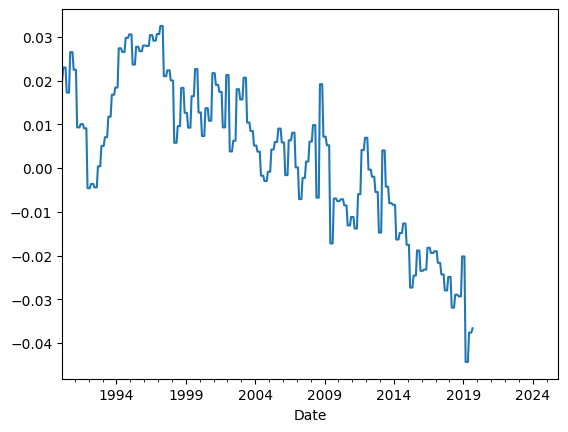

In [ ]:
df['cay'].plot()

In [ ]:
cay_series = df["cay"].astype(float)
exog_vars = ["log_PD", "log_PE", "excess_ret"]
exog = df[exog_vars].astype(float)

kalman_model = sm.tsa.UnobservedComponents(
    endog=cay_series,
    level="local level",
    exog=exog
)

kalman_res = kalman_model.fit(disp=False)
cay_fitted = kalman_res.predict()

df["cay_imputed"] = cay_series.fillna(cay_fitted)
df["cay"] = df["cay_imputed"]

print("# of NaN's after Imputation:", int(df["cay"].isna().sum()))
print("\nTail:")
print(df[["cay"]].tail(12))

# of NaN's after Imputation: 0

Tail:
                 cay
Date                
2024-12-31 -0.045093
2025-01-31 -0.044724
2025-02-28 -0.044849
2025-03-31 -0.043401
2025-04-30 -0.041889
2025-05-31 -0.043407
2025-06-30 -0.044113
2025-07-31 -0.044914
2025-08-31 -0.045102
2025-09-30 -0.045470
2025-10-31 -0.045746
2025-11-30 -0.045546


In [ ]:
df.to_csv("data/final.csv")